In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Innlastning av dataset #

In [2]:
df_links_small = pd.read_csv('data/links_small.csv')
df_links_small.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [3]:
df_links = pd.read_csv('data/links.csv')
df_links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [4]:
df_ratings_small = pd.read_csv('data/ratings_small.csv')
df_ratings_small.head()

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


In [5]:
df_ratings = pd.read_csv('data/ratings.csv')
df_ratings.head()

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


-------------------------------------------------

# Utforskning av data #
Utforsker de ulike csv-filene ved hjelp av .shape, .head(), .dtypes og .info()

## Links_small ##

### .shape ###

In [6]:
df_links_small.shape

(9125, 3)

### .head() ###

In [7]:
df_links_small.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### .dtypes ###

In [8]:
df_links_small.dtypes

movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

### .info() ###

In [9]:
df_links_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9125 entries, 0 to 9124
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  9125 non-null   int64  
 1   imdbId   9125 non-null   int64  
 2   tmdbId   9112 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 214.0 KB


**Observasjon:** links_small har 9 125 filmer og tre ID-kolonner. `movieId` er MovieLens sin ID, `imdbId` er IMDb-ID uten «tt»-prefiks, og `tmdbId` er ID-en som brukes i `movies_metadata`, `credits` og `keywords`. `tmdbId` har bare 9 112 non-null-verdier og er derfor `float64`. Filen fungerer som en koblingstabell mellom ratings og resten av datasettet.

## Links ##

### .shape ###

In [10]:
df_links.shape

(45843, 3)

### .head() ###

In [11]:
df_links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### .dtypes ###

In [12]:
df_links.dtypes

movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

### .info() ###

In [13]:
df_links.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45843 entries, 0 to 45842
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  45843 non-null  int64  
 1   imdbId   45843 non-null  int64  
 2   tmdbId   45624 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 1.0 MB


**Observasjon:** links har 45 843 filmer, omtrent fem ganger så mange som links_small, med de samme tre kolonnene og datatypene. `tmdbId` har 45 624 non-null-verdier. Antallet ligger nær de 45 463 filmene i movies_metadata etter reparasjon, men det betyr ikke nødvendigvis at alle kan kobles (se siste seksjon).

## Ratings_small ##

### .shape ###

In [14]:
df_ratings_small.shape

(100004, 4)

### .head() ###

In [15]:
df_ratings_small.head()

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


### .dtypes ###

In [16]:
df_ratings_small.dtypes

userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

### .info() ###

In [17]:
df_ratings_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100004 entries, 0 to 100003
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100004 non-null  int64  
 1   movieId    100004 non-null  int64  
 2   rating     100004 non-null  float64
 3   timestamp  100004 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


**Observasjon:** ratings_small har 100 004 ratings med fire kolonner. `rating` er `float64` fordi skalaen har halve steg, og `timestamp` er lagret som heltall (Unix-tid), ikke som dato. Ingen kolonner har manglende verdier ifølge `.info()`.

## Ratings ##

### .shape ###

In [18]:
df_ratings.shape

(26024289, 4)

### .head() ###

In [19]:
df_ratings.head()

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


### .dtypes ###

In [20]:
df_ratings.dtypes

userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

### .info() ###

In [21]:
df_ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26024289 entries, 0 to 26024288
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 794.2 MB


**Observasjon:** ratings har 26 024 289 ratings og bruker omtrent 794 MB minne i pandas, altså rundt 260 ganger så mange rader som ratings_small. Kolonnene og datatypene er de samme. Størrelsen har betydning for Part 1: tabellen bør settes inn i batcher og ikke som ett stort kall. `.info()` viser ikke non-null-antall for så store tabeller, så manglende verdier sjekkes eksplisitt nedenfor.

-------------------------------------------------

# Videre analyse av links og ratings #

## Links og links_small ##

### 1. Manglende verdier

In [22]:
print("links_small:\n", df_links_small.isna().sum(), "\n")
print("links:\n", df_links.isna().sum())

links_small:
 movieId     0
imdbId      0
tmdbId     13
dtype: int64 

links:
 movieId      0
imdbId       0
tmdbId     219
dtype: int64


Bare `tmdbId` mangler verdier: 13 av 9 125 rader i links_small og 219 av 45 843 rader i links (omtrent 0,5 %). `movieId` og `imdbId` er komplette. De manglende verdiene er grunnen til at `tmdbId` er `float64`: NaN finnes ikke for vanlige heltall i pandas, så hele kolonnen tvinges over til flyttall.

Filmer uten `tmdbId` kan ikke kobles til `movies_metadata`, `credits` eller `keywords`. Radene beholdes likevel, fordi `movieId` fortsatt kobler dem til ratings, og en manglende ekstern ID gjør ikke ratingene ugyldige. `tmdbId` imputeres ikke: en gjettet ID ville koblet ratings til feil film. Før kobling mot `movies_metadata` bør kolonnen gjøres om til heltall (f.eks. `Int64`, som tåler NaN), slik at `862.0` sammenlignes som `862`.

### 2. Duplikater

In [23]:
for navn, df in [("links_small", df_links_small), ("links", df_links)]:
    print(navn)
    print("  Duplikate movieId:", df["movieId"].duplicated().sum())
    print("  Duplikate imdbId: ", df["imdbId"].duplicated().sum())
    print("  Duplikate tmdbId: ", df["tmdbId"].dropna().duplicated().sum())

links_small
  Duplikate movieId: 0
  Duplikate imdbId:  0
  Duplikate tmdbId:  0
links
  Duplikate movieId: 0
  Duplikate imdbId:  0
  Duplikate tmdbId:  30


In [24]:
# Ser på noen av radene der flere movieId peker på samme tmdbId
tmdb_dup = df_links[df_links["tmdbId"].notna() & df_links["tmdbId"].duplicated(keep=False)]
tmdb_dup.sort_values("tmdbId").head(6)

,movieId,imdbId,tmdbId
5905,6003,290538,4912.0
34144,144606,270288,4912.0
9215,27136,165303,5511.0
7388,7587,62229,5511.0
45197,174533,235679,10991.0
4148,4241,266860,10991.0


`movieId` og `imdbId` er unike i begge filene, så de kan brukes som nøkler. I links peker 30 `tmdbId` på mer enn én `movieId`. Eksempelet viser blant annet at `tmdbId` 4912 er koblet til både `movieId` 6003 og 144606, med ulike `imdbId`. To MovieLens-filmer peker altså på samme TMDB-film, og det er uklart om det er feil i koblingen eller to oppføringer av samme film.

Koblingen links → movies_metadata er derfor ikke helt én-til-én, og ratings for én TMDB-film kan være spredt på flere `movieId`. Radene slettes ikke, fordi det ikke er mulig å avgjøre ut fra links alene hvilken kobling som er riktig. Ved innsetting må det velges om ratingene slås sammen per `tmdbId` eller om bare én `movieId` beholdes. Det gjelder 30 av 45 624 koblinger, så valget har liten effekt på totalen, men det bør dokumenteres.

### 3. Er links_small et delsett av links?

In [25]:
mangler_i_links = ~df_links_small["movieId"].isin(df_links["movieId"])
print("movieId i links_small som ikke finnes i links:", mangler_i_links.sum())
df_links_small[mangler_i_links]

movieId i links_small som ikke finnes i links: 10


,movieId,imdbId,tmdbId
5173,7502,185906,191903.0
7527,77658,81846,205300.0
8045,94466,2085059,NaN
8505,108548,898266,NaN
8507,108583,72500,NaN
8520,108979,213338,314040.0
9062,150856,5189670,374454.0
9118,162376,4574334,410612.0
9123,164977,27660,137608.0
9124,164979,3447228,410803.0


Nesten, men ikke helt: 10 filmer i links_small finnes ikke i links. Tre av dem mangler også `tmdbId`. Small-versjonen er altså ikke et rent utsnitt av den fulle, og de to filene kan ikke behandles som samme datasett i ulik størrelse.

Dette betyr at valget av links-fil må følge valget av ratings-fil: ratings_small bør kobles via links_small, og ratings via links (se også koblingen nederst).

### 4. Oppsummering av Links
links_small har 9 125 og links 45 843 filmer. `movieId` og `imdbId` er unike og komplette i begge. Bare `tmdbId` mangler verdier (13 og 219), og radene beholdes fordi de fortsatt kobler ratings til `movieId`. Ingen ID-er imputeres.

I links peker 30 `tmdbId` på flere `movieId`. Disse slettes ikke, men må håndteres ved innsetting ved å slå sammen eller velge én. links_small er ikke et rent delsett av links (10 filmer mangler), så links-filen må velges i samme størrelse som ratings-filen. `tmdbId` bør konverteres til heltall før kobling mot movies_metadata.

## Ratings og ratings_small ##

### 1. Manglende verdier og duplikater

In [26]:
for navn, df in [("ratings_small", df_ratings_small), ("ratings", df_ratings)]:
    print(navn)
    print("  Manglende verdier totalt:  ", df.isna().sum().sum())
    print("  Helt identiske rader:      ", df.duplicated().sum())
    print("  Duplikate (userId, movieId):", df.duplicated(subset=["userId", "movieId"]).sum())

ratings_small
  Manglende verdier totalt:   0
  Helt identiske rader:       0
  Duplikate (userId, movieId): 0
ratings
  Manglende verdier totalt:   0
  Helt identiske rader:       0
  Duplikate (userId, movieId): 0


Ingen manglende verdier, ingen helt identiske rader og ingen duplikate `(userId, movieId)`-par i noen av filene. Hver bruker har altså vurdert hver film maks én gang, så `(userId, movieId)` fungerer som en naturlig sammensatt nøkkel. Ingen rader trenger å fjernes eller slås sammen.

`.info()` for ratings viste ikke non-null-antall fordi tabellen er stor (pandas hopper over tellingen for over 1,69 mill. rader som standard). Derfor er `isna()` brukt her for å bekrefte at det ikke mangler noe.

### 2. Gyldige ratingverdier

In [27]:
print("ratings_small:", sorted(df_ratings_small["rating"].unique().tolist()))
print("ratings:      ", sorted(df_ratings["rating"].unique().tolist()))

ratings_small: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
ratings:       [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]


Skalaen er 0,5 til 5 i halve steg, med de samme ti verdiene i begge filene. Ingen verdier ligger utenfor skalaen, og det finnes ingen 0-ratinger som kunne vært en kode for «mangler». Ratingene kan derfor brukes direkte uten filtrering.

Merk at skalaen er en annen enn `vote_average` i movies_metadata (0 til 10). Ratings fra de to kildene kan ikke sammenlignes direkte uten å skalere den ene.

### 3. Tidsstempel

`timestamp` er Unix-tid (sekunder siden 1970). Vi konverterer til datetime for å se hvilken periode dataene dekker.

In [28]:
for df in [df_ratings_small, df_ratings]:
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="s")

print("ratings_small:", df_ratings_small["timestamp"].min(), "til", df_ratings_small["timestamp"].max())
print("ratings:      ", df_ratings["timestamp"].min(), "til", df_ratings["timestamp"].max())

ratings_small: 1995-01-09 11:46:49 til 2016-10-16 17:57:24
ratings:       1995-01-09 11:46:44 til 2017-08-04 06:57:50


ratings_small dekker januar 1995 til oktober 2016, og ratings dekker januar 1995 til august 2017. Begge starter samme dag, noe som tyder på at de kommer fra samme MovieLens-kilde, men den fulle filen er nyere. Ingen tidsstempler ligger i framtiden eller rundt 1970 (som ville tydet på 0 eller manglende verdi), så det er ingen åpenbart feil verdier.

Konverteringen er gjort direkte i DataFramene, så `timestamp` er `datetime64` i resten av notebooken. Ved innsetting i MongoDB bør feltet lagres som dato og ikke som heltall, slik at det kan filtreres på tidsperioder.

### 4. Fordeling av ratings

In [29]:
df_ratings["rating"].describe()

count    2.602429e+07
mean     3.528090e+00
std      1.065443e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

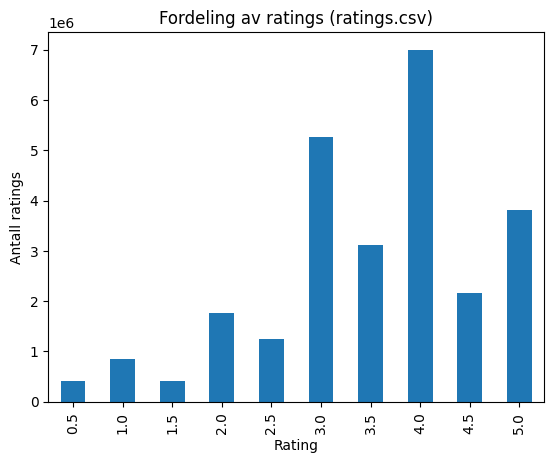

In [30]:
df_ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Fordeling av ratings (ratings.csv)")
plt.xlabel("Rating")
plt.ylabel("Antall ratings")
plt.show()

Gjennomsnittet er 3,53 og medianen 3,5, med standardavvik 1,07. Halvparten av alle ratings ligger mellom 3 og 4. Fordelingen er venstreskjev: 4 er vanligst, og lave ratings er sjeldne. Hele tall brukes oftere enn halve, sannsynligvis fordi brukerne foretrekker «runde» verdier.

Siden de fleste ratings ligger høyt, sier en rating på 3 mindre om en film enn det skalaen tilsier. Ingen verdier fjernes; fordelingen beskriver brukeratferd, ikke feil i dataene.

### 5. Antall ratings per bruker og per film

In [31]:
per_bruker = df_ratings.groupby("userId").size()
per_film = df_ratings.groupby("movieId").size()

print("Antall brukere:", per_bruker.shape[0])
print("Antall filmer: ", per_film.shape[0])
pd.DataFrame({"per bruker": per_bruker.describe(), "per film": per_film.describe()})

Antall brukere: 270896
Antall filmer:  45115


,per bruker,per film
count,270896.000000,45115.000000
mean,96.067454,576.843378
std,205.719606,3037.380582
min,1.000000,1.000000
25%,15.000000,2.000000
50%,30.000000,8.000000
75%,93.000000,69.000000
max,18276.000000,91921.000000


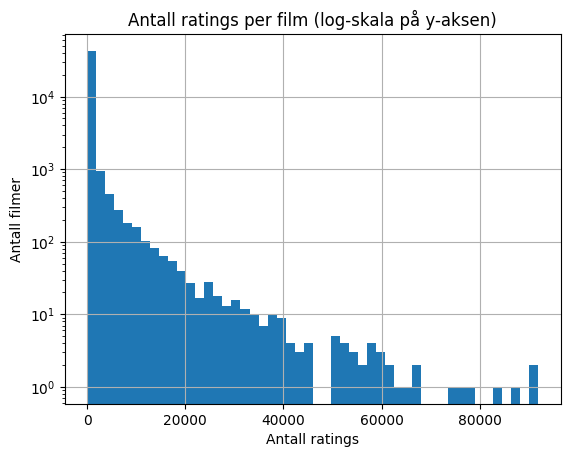

In [32]:
per_film.hist(bins=50, log=True)
plt.title("Antall ratings per film (log-skala på y-aksen)")
plt.xlabel("Antall ratings")
plt.ylabel("Antall filmer")
plt.show()

Det er 270 896 brukere og 45 115 filmer i ratings. Begge fordelingene er svært høyreskjeve: gjennomsnittet ligger langt over medianen.

- **Per film:** medianen er bare 8 ratings, og en fjerdedel av filmene har 2 eller færre. De mest populære har over 90 000 (maks 91 921). Gjennomsnittet på 577 trekkes opp av noen få svært populære filmer.
- **Per bruker:** medianen er 30 ratings og gjennomsnittet 96. Den mest aktive brukeren har 18 276 ratings, noe som er uvanlig mye for én person.

En gjennomsnittsrating for en film med få stemmer er lite pålitelig: én enkelt 5-er gir toppscore. I analysene bør vi derfor sette en nedre grense for antall ratings før filmer rangeres. Ekstremt aktive brukere slettes ikke, fordi det ikke er dokumentert at ratingene deres er feil, men de kan påvirke resultater som teller per bruker.

### 6. ratings_small vs. ratings

In [33]:
print("ratings_small: brukere =", df_ratings_small["userId"].nunique(), ", filmer =", df_ratings_small["movieId"].nunique())
print("ratings:       brukere =", df_ratings["userId"].nunique(), ", filmer =", df_ratings["movieId"].nunique())

felles = df_ratings_small.merge(df_ratings, on=["userId", "movieId"])
print("Par (userId, movieId) fra ratings_small som også finnes i ratings:", len(felles), "av", len(df_ratings_small))

ratings_small: brukere = 671 , filmer = 9066
ratings:       brukere = 270896 , filmer = 45115
Par (userId, movieId) fra ratings_small som også finnes i ratings: 6361 av 100004


ratings_small har 671 brukere og 9 066 filmer, mot 270 896 brukere og 45 115 filmer i ratings. Bare 6 361 av 100 004 par (omtrent 6 %) fra ratings_small finnes igjen i ratings. Hvis ratings_small var et utsnitt av ratings, skulle alle parene gått igjen.

ratings_small er derfor **ikke** et utsnitt av ratings. `userId` betyr trolig ikke samme person i de to filene, og de få treffene kan være tilfeldige. De to filene må ikke blandes eller slås sammen, og analysene må bruke én av dem konsekvent.

### 7. Oppsummering av Ratings
ratings_small har 100 004 og ratings 26 024 289 rader. Ingen av filene har manglende verdier, duplikater eller ratings utenfor skalaen 0,5 til 5. `(userId, movieId)` er unik og kan brukes som nøkkel. `timestamp` er konvertert fra Unix-tid til dato og dekker 1995 til 2016/2017.

Fordelingen av ratings er venstreskjev med gjennomsnitt 3,53. Antall ratings per film og per bruker er svært skjevt, og medianfilmen har bare 8 ratings. I rangeringer bør det derfor brukes en nedre grense for antall ratings. Ingen rader er fjernet.

ratings_small er ikke et utsnitt av ratings, og de to filene må ikke blandes.

## Kobling mellom datasettene ##

ratings → links via `movieId`, og links → movies_metadata via `tmdbId` = `id`. Vi sjekker hvor mye som faktisk lar seg koble.

In [34]:
print("movieId i ratings som finnes i links:            ", df_ratings["movieId"].isin(df_links["movieId"]).mean())
print("movieId i ratings_small som finnes i links_small:", df_ratings_small["movieId"].isin(df_links_small["movieId"]).mean())
print("movieId i ratings_small som finnes i links:      ", df_ratings_small["movieId"].isin(df_links["movieId"]).mean())

movieId i ratings som finnes i links:             1.0
movieId i ratings_small som finnes i links_small: 1.0
movieId i ratings_small som finnes i links:       0.999540018399264


In [35]:
# Leser bare id-kolonnen fra movies_metadata. Feilformaterte id-er (datoer) blir NaN.
metadata_id = pd.to_numeric(pd.read_csv("data/movies_metadata.csv", usecols=["id"])["id"], errors="coerce")

tmdb = df_links["tmdbId"].dropna()
print("tmdbId i links som finnes i movies_metadata:", tmdb.isin(metadata_id).mean())
print("Antall som ikke finnes:", (~tmdb.isin(metadata_id)).sum())

tmdbId i links som finnes i movies_metadata: 0.996471155532176
Antall som ikke finnes: 161


Koblingen er nesten fullstendig:

- Alle `movieId` i ratings finnes i links, og alle `movieId` i ratings_small finnes i links_small.
- Mot den fulle links-filen mangler 46 ratings i ratings_small (de 10 filmene fra seksjon 3). Det bekrefter at ratings_small hører sammen med links_small.
- Av 45 624 `tmdbId` i links finnes 161 (omtrent 0,35 %) ikke i movies_metadata. Ratings på disse filmene kan ikke knyttes til metadata, så de mister tittel, sjanger osv. ved innsetting.
- links har 45 843 filmer, mens ratings bare har ratings for 45 115. Rundt 730 filmer i links har altså ingen ratings.

Ratings uten metadata beholdes, fordi ratingen i seg selv er gyldig, men de vil falle bort i analyser som krever tittel eller sjanger. Merk at sjekken mot movies_metadata leser `id` direkte fra rå CSV, med feilformaterte ID-er gjort om til NaN. Etter reparasjonen i eda_tahir kan tallet derfor bli litt annerledes.

## Oppsummering og gjenstående valg ##
Ingen av de fire filene trengte rensing av selve radene: det finnes ingen duplikater, ingen ugyldige ratings og ingen manglende verdier utenom `tmdbId` i links. Ingen rader er slettet, og ingen verdier er imputert. Den eneste endringen i dataene er at `timestamp` er konvertert til dato.

Valg som må tas før innsetting:

1. **Hvilket ratings-sett som brukes.** ratings og ratings_small er ikke delsett av hverandre og må ikke blandes. ratings_small må kobles via links_small, og ratings via links.
2. **Duplikate `tmdbId`.** 30 TMDB-filmer har flere `movieId`. Det må bestemmes om ratingene slås sammen per `tmdbId` eller om bare én `movieId` beholdes.
3. **Filmer uten metadata.** Ratings på filmer uten `tmdbId`, eller med `tmdbId` som ikke finnes i movies_metadata, beholdes, men faller bort i analyser som krever tittel eller sjanger.
4. **Datatyper.** `tmdbId` gjøres om til heltall før kobling, og `timestamp` lagres som dato.
5. **Få ratings per film.** Analyser som rangerer filmer på gjennomsnittsrating bør ha en nedre grense for antall ratings.